### **We use the prtrained model for glacier mapping**   


In [2]:
import torch       
import numpy as np      
import pandas as pd     
import rasterio as rio    
from pyrsimg import imsShow      
from pyrsimg import img2patch    
from pyrsimg import metrics_segm    
from model import unet_cnn_timm 


/home/xin/miniconda3/envs/setp-cryo/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
## load trained model
model = unet_cnn_timm(backbone_name='efficientnet_b0', pretrained=False)
path_trained_model = 'model/weights/unet_efficientnet_b0_09464.pth'
model.load_state_dict(torch.load(path_trained_model, weights_only=True, map_location='cuda:0'))
model.eval();


Output channels from encoder stages: [16, 24, 40, 112, 320]


### one scene prediction

In [8]:
path_scene = 'data/rsimg/l5_scene_01_nor.tif'
path_dem = 'data/rsimg/l5_scene_01_dem.tif'

In [9]:
# ## read data
with rio.open(path_scene) as scene_rio, rio.open(path_dem) as dem_rio:
    scene_sdem_arr = np.concatenate([scene_rio.read(), dem_rio.read()], axis=0)
    scene_sdem_arr = scene_sdem_arr.transpose((1, 2, 0))  # (H,W,C)
scene_sdem_arr.shape


(1704, 1714, 7)

In [11]:
def model_infer(scene_arr, model):
    ### image to patches
    imgPat_obj = img2patch(img=scene_arr, patch_size=512, edge_overlay = 40)
    patch_arr_list = imgPat_obj.toPatch()
    # channel first and numpy array to torch tensor
    patch_list = [torch.from_numpy(patch.transpose(2,0,1)).float() for patch in patch_arr_list]  
    with torch.no_grad():  ## save 
        presult_list = [model(patch[np.newaxis, :])[0] for patch in patch_list]
    ## channel last and torch tensor to numpy array
    presult_arr_list = [np.squeeze(patch.detach().numpy().transpose(0,2,3,1), axis = 0) 
                                    for patch in presult_list ]       
    ## patch to image
    gla_pred_prob = imgPat_obj.toImage(presult_arr_list)
    gla_pred_cla = np.where(gla_pred_prob>0.5, 1, 0) 
    gla_pred_cla = gla_pred_cla.squeeze().astype(np.uint8)     
    return gla_pred_cla

gla_pred_cla = model_infer(scene_arr=scene_sdem_arr, model=model) 


array([<Axes: title={'center': 'input image'}>,
       <Axes: title={'center': 'dem'}>,
       <Axes: title={'center': 'gla_pred_cla'}>], dtype=object)

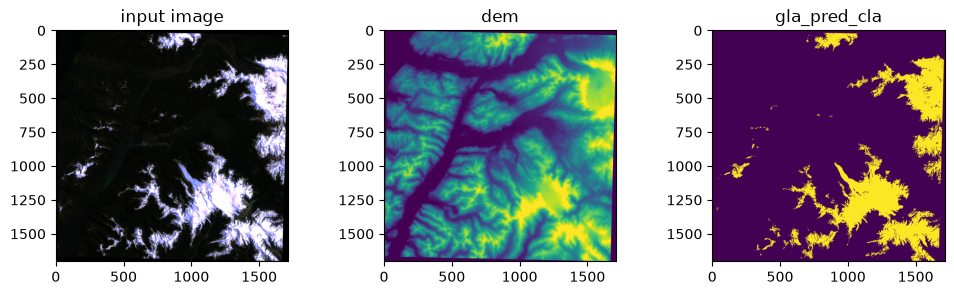

In [ ]:
### show the results
imsShow([scene_sdem_arr, scene_sdem_arr[:,:,-1], gla_pred_cla], 
        clip_list=[2, 2, 0], 
        img_name_list = ['input image', 'dem', 'gla_pred_cla'],
        figsize=(12, 3));


### Batch processing